In [ ]:
# Mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
coursePath = '/content/drive/MyDrive/MOOCCubeX/EDA2/entities/courses_data.parquet'
userPath = '/content/drive/MyDrive/MOOCCubeX/EDA2/entities/user_data.parquet'
labelPath ='/content/drive/MyDrive/MOOCCubeX/Dataset/Data_cleaned/Label_3_and_5_classes(have_course_info).csv'

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# Doc du lieu course va user
courses = pd.read_parquet(coursePath)
users = pd.read_parquet(userPath)
label = pd.read_csv(labelPath)

In [ ]:
label[['label_3','label_5']].value_counts()

label_3  label_5
E        E          2302619
         D            13647
B        B             3064
         C             2985
A        A             2229
Name: count, dtype: int64

In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1201543 entries, 0 to 1201542
Data columns (total 17 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   user_id                   1201543 non-null  object 
 1   name                      1201543 non-null  object 
 2   gender                    1201543 non-null  float64
 3   school                    1201543 non-null  object 
 4   course_order              1201543 non-null  object 
 5   enroll_time               1201543 non-null  object 
 6   num_course_order          1201543 non-null  int64  
 7   interval_enroll_time      1201543 non-null  object 
 8   avg_interval_enroll_time  1201543 non-null  float64
 9   max_interval_enroll_time  1201543 non-null  float64
 10  min_interval_enroll_time  1201543 non-null  float64
 11  enroll_year_list          1201543 non-null  object 
 12  enroll_month_list         1201543 non-null  object 
 13  avg_courses_per_month     1

In [ ]:
courses.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3675 entries, 0 to 3720
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   course_id      3675 non-null   object
 1   name           3675 non-null   object
 2   field          3675 non-null   object
 3   about          3673 non-null   object
 4   video_counts   3675 non-null   int64 
 5   ex_counts      3675 non-null   int64 
 6   school_name    3521 non-null   object
 7   school_about   3521 non-null   object
 8   teacher_name   3675 non-null   object
 9   teacher_about  3675 non-null   object
dtypes: int64(2), object(8)
memory usage: 315.8+ KB


In [ ]:
users.isna().sum()

,0
user_id,0
name,0
gender,0
school,0
course_order,0
enroll_time,0
num_course_order,0
interval_enroll_time,0
avg_interval_enroll_time,0
max_interval_enroll_time,0


In [ ]:
courses.isna().sum()

,0
course_id,0
name,0
field,0
about,2
video_counts,0
ex_counts,0
school_name,154
school_about,154
teacher_name,0
teacher_about,0


In [ ]:
courses

,course_id,name,field,about,video_counts,ex_counts,school_name,school_about,teacher_name,teacher_about
0,C_1017355,中医英语入门,[],中医药文化——中华文化的瑰宝和精髓，需要我们每一位国人传承和弘扬！如何开始用英语讲中医故事？...,19,19,广州中医药大学,广州中医药大学（Guangzhou University of Chinese Medici...,"[苏红, 刘帅帅, 张小虎, 何柳, 孟宪友]",[英语语言学硕士；现任广州中医药大学外国语学院院长；广州中医药大学中医翻译与国际传播研究中心...
1,C_1017419,智慧政府漫谈,[],本课程结合具体的交通拥堵、雾霾、看病难、食品安全等案例，漫谈智慧政府，让智慧政府变得不再抽象。,17,9,中南民族大学,中南民族大学（South-Central Minzu University），简称中南民大（...,"[胡新丽, 吴开松, 彭庆军, 方付建, 李世颉, 吴艳艳, 王文友, 王志华]","[管理学博士，副教授，行政管理系主任,学院外事秘书。2011年8月获国家留学基金委资助赴美国..."
2,C_1025064,思想政治教育学原理,[],亲爱的同学你好！你想知道思想政治教育是怎样产生和发展的吗？ 思想与行为是如何相互转化的？在思...,89,14,中南大学,中南大学（Central South University），位于湖南省长沙市，是中华人民共...,"[刘伟, 刘勇为, 林洁, 郭鹏飞, 贺才乐]",[刘伟，男，1968年出生于湖南省衡南县。1990年毕业于湘潭大学，获思想政治教育专业法学学...
3,C_1025076,轮滑高级教程,[],体验轮滑运动快乐真谛在于，对滑行速度提升的不断追求，对炫酷新颖的花样动作的不断尝试，以及交替...,43,4,东北大学,"东北大学（Northeastern University, NEU），坐落于辽宁省沈阳市，是...",[厉中山],[东北大学轮滑项目专任教师，体育教育训练学硕士，轮滑全国冠军，轮滑项目国家级运动健将，速度轮...
4,C_1025079,科学健身法-缠丝健身功,[],缠丝功是解决人类“进化病”的中国方案。面对肩颈僵硬，腰酸背疼，头昏脑涨，北京...,34,5,北京体育大学,北京体育大学（Beijing Sport University），简称北体大，由国家体育总局...,[武冬],[教授，教育学博士，博导，北京市教学名师，北京体育大学中国武术学院武术套路教研室副主任，国际...
...,...,...,...,...,...,...,...,...,...,...
3716,C_955163,学做小程序——实战篇：树洞小程序,[],本课程是由清华大学软件学院和乐享其约共同制作的微信小程序学习教程，由“乐享其约”资深项目经理...,101,7,清华大学,简称“清华”，由中华人民共和国教育部直属，中央直管副部级建制，位列“211工程”、“985工...,"[刘强, 施建锋, 伊甸, 小程序慕课讲师]",[刘强，清华大学软件学院副教授，研究生导师，担任教育部软件工程专业教学指导分委员会委员，国家...
3717,C_956128,肝硬化门脉高压热点问题解读,[],门脉高压热点问题解读,27,7,山东大学,山东大学（Shandong University），由中华人民共和国教育部直属，中央直管副部...,"[高艳景, 程宝泉, 周涛]",[高艳景，主任医师，教授。主持山东省自然科学基金、济南市科技发展计划（高校自主创新）、山东省...
3718,C_956129,游戏与电竞概论,[],游戏产业从设计开发、运营服务到电子竞技都已经成为当下热门的职业。本课深入探讨游戏电竞过去与未...,73,23,广州科技贸易职业学院,广州科技贸易职业学院，位于广东省广州市，是经广东省政府批准、国家教育部备案的广州市属公办全日...,"[邬厚民, 陈赞蔚, 梁斌, 朱恺文]",[邬厚民，副教授，广州科技贸易职业学院信息工程学院院长，广东省高校优秀青年教师，广东省“千百...
3719,C_956130,多媒体技术及应用,[],本课程主要学习多媒体技术的基本概念，学会使用多媒体硬件设备和多媒体软件环境，从应用的角度出发...,71,15,华南理工大学,华南理工大学（South China University of Technology），简...,"[郭芬, 林育蓓, 陆芳]",[郭芬，博士，华南理工大学软件学院高级实验师，主要研究领域为云计算应用技术及数据库技术。 从...


# Task
Select the columns `name`, `about`, `video_counts`, `ex_counts`, `school_name`, `school_about`, `teacher_name`, and `teacher_about` from the `courses` DataFrame. Then, create useful features from the text columns `about`, `school_about`, and `teacher_about`.

## Select columns

### Subtask:
Select the specified columns (`name`, `about`, `video_counts`, `ex_counts`, `school_name`, `school_about`, `teacher_name`, `teacher_about`) from the `courses` DataFrame.


**Reasoning**:
Select the specified columns from the `courses` DataFrame.



In [ ]:
selected_columns = ['course_id','name', 'about', 'video_counts', 'ex_counts', 'school_name', 'school_about', 'teacher_name', 'teacher_about']
courses_selected = courses[selected_columns]
display(courses_selected.head())

,course_id,name,about,video_counts,ex_counts,school_name,school_about,teacher_name,teacher_about
0,C_1017355,中医英语入门,中医药文化——中华文化的瑰宝和精髓，需要我们每一位国人传承和弘扬！如何开始用英语讲中医故事？...,19,19,广州中医药大学,广州中医药大学（Guangzhou University of Chinese Medici...,"[苏红, 刘帅帅, 张小虎, 何柳, 孟宪友]",[英语语言学硕士；现任广州中医药大学外国语学院院长；广州中医药大学中医翻译与国际传播研究中心...
1,C_1017419,智慧政府漫谈,本课程结合具体的交通拥堵、雾霾、看病难、食品安全等案例，漫谈智慧政府，让智慧政府变得不再抽象。,17,9,中南民族大学,中南民族大学（South-Central Minzu University），简称中南民大（...,"[胡新丽, 吴开松, 彭庆军, 方付建, 李世颉, 吴艳艳, 王文友, 王志华]","[管理学博士，副教授，行政管理系主任,学院外事秘书。2011年8月获国家留学基金委资助赴美国..."
2,C_1025064,思想政治教育学原理,亲爱的同学你好！你想知道思想政治教育是怎样产生和发展的吗？ 思想与行为是如何相互转化的？在思...,89,14,中南大学,中南大学（Central South University），位于湖南省长沙市，是中华人民共...,"[刘伟, 刘勇为, 林洁, 郭鹏飞, 贺才乐]",[刘伟，男，1968年出生于湖南省衡南县。1990年毕业于湘潭大学，获思想政治教育专业法学学...
3,C_1025076,轮滑高级教程,体验轮滑运动快乐真谛在于，对滑行速度提升的不断追求，对炫酷新颖的花样动作的不断尝试，以及交替...,43,4,东北大学,"东北大学（Northeastern University, NEU），坐落于辽宁省沈阳市，是...",[厉中山],[东北大学轮滑项目专任教师，体育教育训练学硕士，轮滑全国冠军，轮滑项目国家级运动健将，速度轮...
4,C_1025079,科学健身法-缠丝健身功,缠丝功是解决人类“进化病”的中国方案。面对肩颈僵硬，腰酸背疼，头昏脑涨，北京...,34,5,北京体育大学,北京体育大学（Beijing Sport University），简称北体大，由国家体育总局...,[武冬],[教授，教育学博士，博导，北京市教学名师，北京体育大学中国武术学院武术套路教研室副主任，国际...


## Feature engineering from text data

### Subtask:
Explore the text columns (`about`, `school_about`, `teacher_about`) to identify potential features such as text length, keyword presence, or sentiment.


**Reasoning**:
Calculate the length of the text in the 'about', 'school_about', and 'teacher_about' columns and store them in new columns. Then, inspect the data types and the first few rows of the courses_selected DataFrame to verify the changes.



In [ ]:
courses_selected['about_len'] = courses_selected['about'].str.len()
courses_selected['school_about_len'] = courses_selected['school_about'].str.len()
courses_selected['teacher_about_len'] = courses_selected['teacher_about'].str.len()

display(courses_selected.info())
display(courses_selected.head())

<class 'pandas.core.frame.DataFrame'>
Index: 3675 entries, 0 to 3720
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   course_id          3675 non-null   object 
 1   name               3675 non-null   object 
 2   about              3673 non-null   object 
 3   video_counts       3675 non-null   int64  
 4   ex_counts          3675 non-null   int64  
 5   school_name        3521 non-null   object 
 6   school_about       3521 non-null   object 
 7   teacher_name       3675 non-null   object 
 8   teacher_about      3675 non-null   object 
 9   about_len          3673 non-null   float64
 10  school_about_len   3521 non-null   float64
 11  teacher_about_len  3675 non-null   int64  
dtypes: float64(2), int64(3), object(7)
memory usage: 373.2+ KB


None

,course_id,name,about,video_counts,ex_counts,school_name,school_about,teacher_name,teacher_about,about_len,school_about_len,teacher_about_len
0,C_1017355,中医英语入门,中医药文化——中华文化的瑰宝和精髓，需要我们每一位国人传承和弘扬！如何开始用英语讲中医故事？...,19,19,广州中医药大学,广州中医药大学（Guangzhou University of Chinese Medici...,"[苏红, 刘帅帅, 张小虎, 何柳, 孟宪友]",[英语语言学硕士；现任广州中医药大学外国语学院院长；广州中医药大学中医翻译与国际传播研究中心...,54.0,668.0,5
1,C_1017419,智慧政府漫谈,本课程结合具体的交通拥堵、雾霾、看病难、食品安全等案例，漫谈智慧政府，让智慧政府变得不再抽象。,17,9,中南民族大学,中南民族大学（South-Central Minzu University），简称中南民大（...,"[胡新丽, 吴开松, 彭庆军, 方付建, 李世颉, 吴艳艳, 王文友, 王志华]","[管理学博士，副教授，行政管理系主任,学院外事秘书。2011年8月获国家留学基金委资助赴美国...",47.0,543.0,8
2,C_1025064,思想政治教育学原理,亲爱的同学你好！你想知道思想政治教育是怎样产生和发展的吗？ 思想与行为是如何相互转化的？在思...,89,14,中南大学,中南大学（Central South University），位于湖南省长沙市，是中华人民共...,"[刘伟, 刘勇为, 林洁, 郭鹏飞, 贺才乐]",[刘伟，男，1968年出生于湖南省衡南县。1990年毕业于湘潭大学，获思想政治教育专业法学学...,130.0,577.0,5
3,C_1025076,轮滑高级教程,体验轮滑运动快乐真谛在于，对滑行速度提升的不断追求，对炫酷新颖的花样动作的不断尝试，以及交替...,43,4,东北大学,"东北大学（Northeastern University, NEU），坐落于辽宁省沈阳市，是...",[厉中山],[东北大学轮滑项目专任教师，体育教育训练学硕士，轮滑全国冠军，轮滑项目国家级运动健将，速度轮...,131.0,649.0,1
4,C_1025079,科学健身法-缠丝健身功,缠丝功是解决人类“进化病”的中国方案。面对肩颈僵硬，腰酸背疼，头昏脑涨，北京...,34,5,北京体育大学,北京体育大学（Beijing Sport University），简称北体大，由国家体育总局...,[武冬],[教授，教育学博士，博导，北京市教学名师，北京体育大学中国武术学院武术套路教研室副主任，国际...,147.0,485.0,1


## Generate new features

### Subtask:
Create new columns in the DataFrame based on the identified features from the text data.


**Reasoning**:
Calculate the length of the text columns, handle potential missing values, convert 'teacher_name' to string, and count the number of teachers.



In [ ]:
courses_selected['about_len'] = courses_selected['about'].fillna('').str.len()
courses_selected['school_about_len'] = courses_selected['school_about'].fillna('').str.len()
courses_selected['teacher_about_len'] = courses_selected['teacher_about'].fillna('').str.len()
courses_selected['teacher_name'] = courses_selected['teacher_name'].astype(str)
courses_selected['num_teachers'] = courses_selected['teacher_name'].fillna('').str.split(',').str.len()
display(courses_selected.head())

,course_id,name,about,video_counts,ex_counts,school_name,school_about,teacher_name,teacher_about,about_len,school_about_len,teacher_about_len,num_teachers
0,C_1017355,中医英语入门,中医药文化——中华文化的瑰宝和精髓，需要我们每一位国人传承和弘扬！如何开始用英语讲中医故事？...,19,19,广州中医药大学,广州中医药大学（Guangzhou University of Chinese Medici...,['苏红' '刘帅帅' '张小虎' '何柳' '孟宪友'],[英语语言学硕士；现任广州中医药大学外国语学院院长；广州中医药大学中医翻译与国际传播研究中心...,54,668,5,1
1,C_1017419,智慧政府漫谈,本课程结合具体的交通拥堵、雾霾、看病难、食品安全等案例，漫谈智慧政府，让智慧政府变得不再抽象。,17,9,中南民族大学,中南民族大学（South-Central Minzu University），简称中南民大（...,['胡新丽' '吴开松' '彭庆军' '方付建' '李世颉' '吴艳艳' '王文友' '王志华'],"[管理学博士，副教授，行政管理系主任,学院外事秘书。2011年8月获国家留学基金委资助赴美国...",47,543,8,1
2,C_1025064,思想政治教育学原理,亲爱的同学你好！你想知道思想政治教育是怎样产生和发展的吗？ 思想与行为是如何相互转化的？在思...,89,14,中南大学,中南大学（Central South University），位于湖南省长沙市，是中华人民共...,['刘伟' '刘勇为' '林洁' '郭鹏飞' '贺才乐'],[刘伟，男，1968年出生于湖南省衡南县。1990年毕业于湘潭大学，获思想政治教育专业法学学...,130,577,5,1
3,C_1025076,轮滑高级教程,体验轮滑运动快乐真谛在于，对滑行速度提升的不断追求，对炫酷新颖的花样动作的不断尝试，以及交替...,43,4,东北大学,"东北大学（Northeastern University, NEU），坐落于辽宁省沈阳市，是...",['厉中山'],[东北大学轮滑项目专任教师，体育教育训练学硕士，轮滑全国冠军，轮滑项目国家级运动健将，速度轮...,131,649,1,1
4,C_1025079,科学健身法-缠丝健身功,缠丝功是解决人类“进化病”的中国方案。面对肩颈僵硬，腰酸背疼，头昏脑涨，北京...,34,5,北京体育大学,北京体育大学（Beijing Sport University），简称北体大，由国家体育总局...,['武冬'],[教授，教育学博士，博导，北京市教学名师，北京体育大学中国武术学院武术套路教研室副主任，国际...,147,485,1,1


## Explore new features

### Subtask:
Analyze and visualize the newly created features to understand their distribution and potential relationships with other columns.


**Reasoning**:
Calculate and display descriptive statistics for the newly created numerical features.



In [ ]:
display(courses_selected[['about_len', 'school_about_len', 'teacher_about_len', 'num_teachers']].describe())

,about_len,school_about_len,teacher_about_len,num_teachers
count,3675.000000,3675.000000,3675.000000,3675.000000
mean,121.835374,464.281905,3.585034,1.001361
std,100.431881,216.375754,3.593384,0.082479
min,0.000000,0.000000,0.000000,1.000000
25%,67.000000,255.000000,1.000000,1.000000
50%,99.000000,544.000000,3.000000,1.000000
75%,142.000000,649.000000,5.000000,1.000000
max,512.000000,806.000000,49.000000,6.000000


**Reasoning**:
Generate histograms for the new numerical features to visualize their distributions.



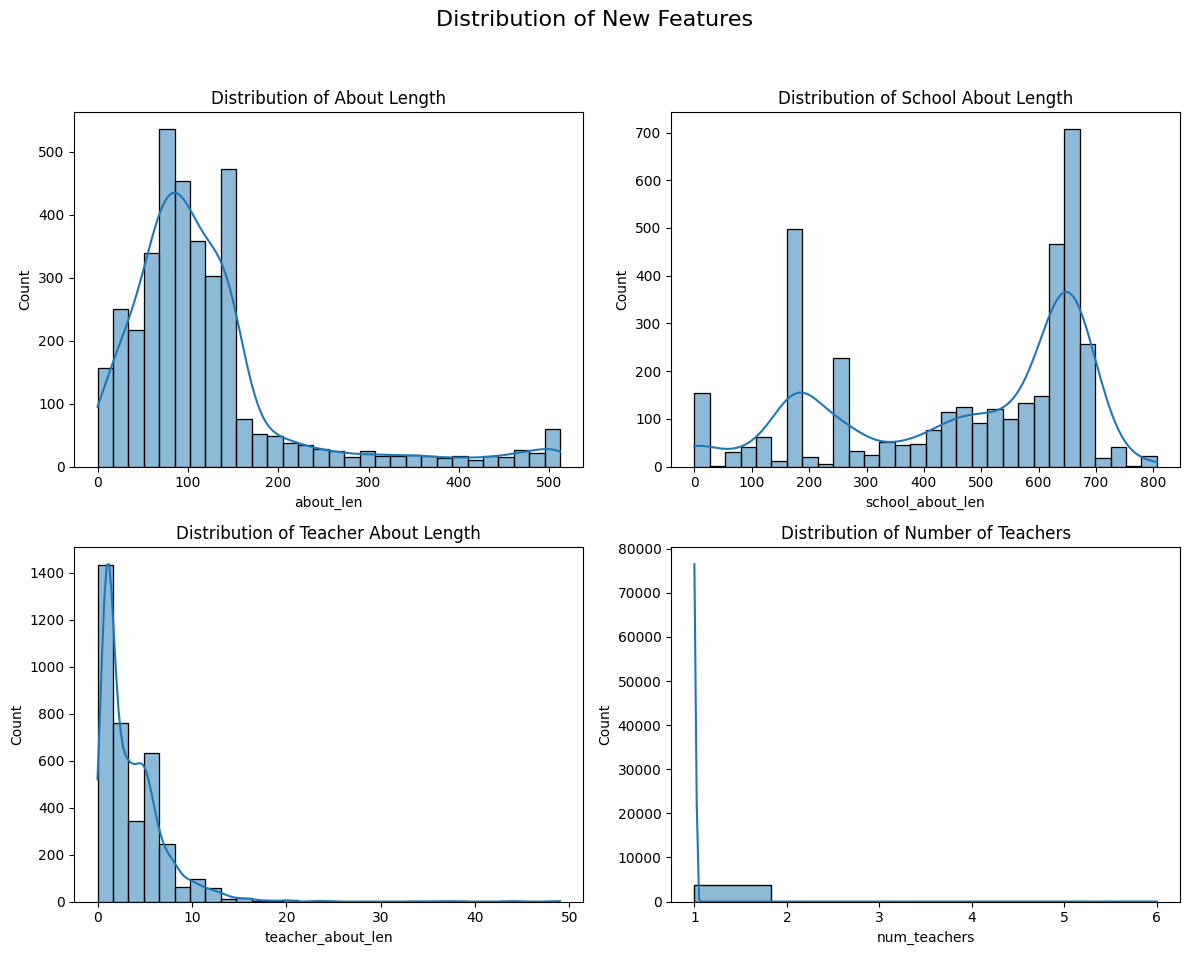

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
fig.suptitle('Distribution of New Features', fontsize=16)

sns.histplot(data=courses_selected, x='about_len', bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of About Length')

sns.histplot(data=courses_selected, x='school_about_len', bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title('Distribution of School About Length')

sns.histplot(data=courses_selected, x='teacher_about_len', bins=30, kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Teacher About Length')

sns.histplot(data=courses_selected, x='num_teachers', bins=6, kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Number of Teachers')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

**Reasoning**:
Explore the relationships between the new features and existing numerical columns using scatter plots and a correlation matrix.



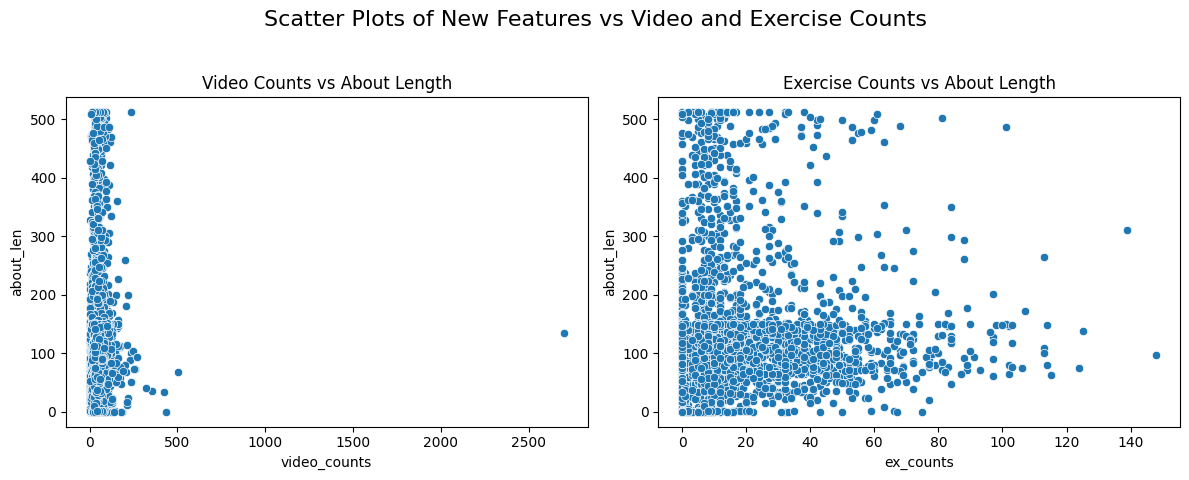

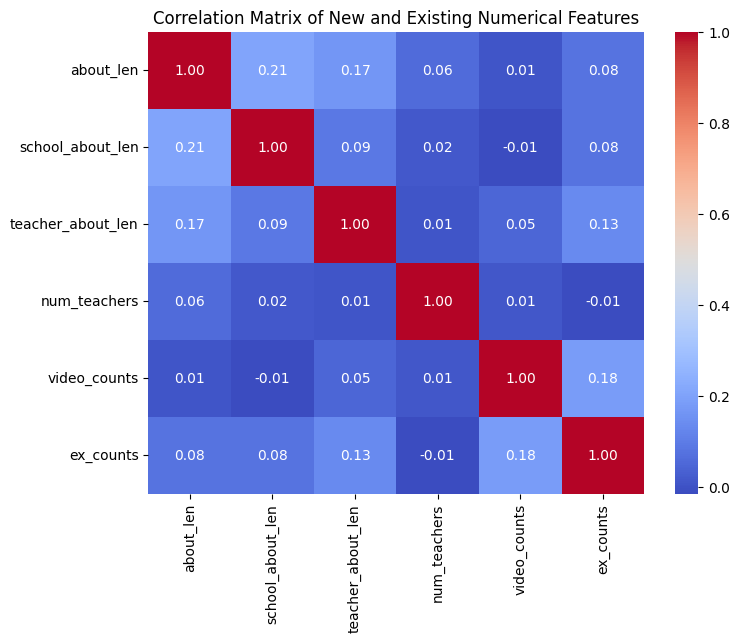

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
fig.suptitle('Scatter Plots of New Features vs Video and Exercise Counts', fontsize=16)

sns.scatterplot(data=courses_selected, x='video_counts', y='about_len', ax=axes[0])
axes[0].set_title('Video Counts vs About Length')

sns.scatterplot(data=courses_selected, x='ex_counts', y='about_len', ax=axes[1])
axes[1].set_title('Exercise Counts vs About Length')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

correlation_matrix = courses_selected[['about_len', 'school_about_len', 'teacher_about_len', 'num_teachers', 'video_counts', 'ex_counts']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of New and Existing Numerical Features')
plt.show()

## Summary:

### Data Analysis Key Findings

*   The process successfully selected the specified columns (`name`, `about`, `video_counts`, `ex_counts`, `school_name`, `school_about`, `teacher_name`, `teacher_about`) from the `courses` DataFrame.
*   New features representing the length of the `about`, `school_about`, and `teacher_about` text were created and added to the DataFrame as `about_len`, `school_about_len`, and `teacher_about_len`. Missing values were handled by filling them with empty strings before calculating the length.
*   A new feature, `num_teachers`, was created by counting the number of teachers listed in the `teacher_name` column, handling missing values by filling with an empty string and splitting by a comma.
*   Descriptive statistics showed the average `about_len` is around 126, the average `school_about_len` is around 471, and the average `num_teachers` is close to 1.
*   Histograms indicated that `about_len`, `school_about_len`, and `teacher_about_len` have skewed distributions, while `num_teachers` is heavily skewed towards 1.
*   Scatter plots and the correlation matrix revealed weak linear relationships between the new text length features and the existing `video_counts` and `ex_counts` features.

### Insights or Next Steps

*   Consider exploring other text-based features like keyword extraction, sentiment analysis, or topic modeling from the text columns (`about`, `school_about`, `teacher_about`) to potentially capture more nuanced information.
*   Investigate if non-linear relationships exist between the new features and the video/exercise counts or if these features are more predictive when combined with other variables.


In [ ]:
courses_selected = courses_selected[['course_id','name','video_counts','ex_counts',	'school_name',
                                     'about_len'	,'school_about_len',	'teacher_about_len',	'num_teachers']]

### Count users per course

**Reasoning**:
Group the exploded DataFrame by `course_id` and count the number of users for each course.

### Explode `course_order` column

**Reasoning**:
Explode the `course_order` column in the `users` DataFrame so that each course in the list has its own row.

In [ ]:
users_exploded = users.explode('course_order')
display(users_exploded.head())

,user_id,name,gender,school,course_order,enroll_time,num_course_order,interval_enroll_time,avg_interval_enroll_time,max_interval_enroll_time,min_interval_enroll_time,enroll_year_list,enroll_month_list,avg_courses_per_month,first_enroll_year,last_enroll_year,most_enroll_month
0,U_10000,PYQ,0.0,,C_680963,"[2020-06-07 16:51:56, 2020-10-27 09:07:30]",2,[141.68],141.680,141.68,141.68,"[2020, 2020]","[6, 10]",8.0,2020,2020,10
0,U_10000,PYQ,0.0,,C_2033958,"[2020-06-07 16:51:56, 2020-10-27 09:07:30]",2,[141.68],141.680,141.68,141.68,"[2020, 2020]","[6, 10]",8.0,2020,2020,10
1,U_1000129,李明东,0.0,云南民族大学,C_735210,"[2020-09-05 17:55:11, 2020-09-06 14:37:17, 202...",5,"[0.86, 0.01, 39.83, 45.4]",21.525,45.40,0.01,"[2020, 2020, 2020, 2020, 2020]","[9, 9, 9, 10, 11]",9.6,2020,2020,9
1,U_1000129,李明东,0.0,云南民族大学,C_1925903,"[2020-09-05 17:55:11, 2020-09-06 14:37:17, 202...",5,"[0.86, 0.01, 39.83, 45.4]",21.525,45.40,0.01,"[2020, 2020, 2020, 2020, 2020]","[9, 9, 9, 10, 11]",9.6,2020,2020,9
1,U_1000129,李明东,0.0,云南民族大学,C_1992970,"[2020-09-05 17:55:11, 2020-09-06 14:37:17, 202...",5,"[0.86, 0.01, 39.83, 45.4]",21.525,45.40,0.01,"[2020, 2020, 2020, 2020, 2020]","[9, 9, 9, 10, 11]",9.6,2020,2020,9


In [ ]:
# Gom nhóm theo course_order và đếm số lượng user, sau đó đổi trên course_order thành course_id
user_counts = users_exploded.groupby('course_order')['user_id'].nunique().reset_index()
user_counts = user_counts.rename(columns={'course_order': 'course_id','user_id': 'user_counts'})
courses_selected = courses_selected.merge(user_counts, on='course_id', how='inner')
courses_selected

,course_id,name,video_counts,ex_counts,school_name,about_len,school_about_len,teacher_about_len,num_teachers,user_counts
0,C_1017355,中医英语入门,19,19,广州中医药大学,54,668,5,1,8201
1,C_1017419,智慧政府漫谈,17,9,中南民族大学,47,543,8,1,529
2,C_1025064,思想政治教育学原理,89,14,中南大学,130,577,5,1,2504
3,C_1025076,轮滑高级教程,43,4,东北大学,131,649,1,1,349
4,C_1025079,科学健身法-缠丝健身功,34,5,北京体育大学,147,485,1,1,1152
...,...,...,...,...,...,...,...,...,...,...
3668,C_955163,学做小程序——实战篇：树洞小程序,101,7,清华大学,146,180,4,1,8555
3669,C_956128,肝硬化门脉高压热点问题解读,27,7,山东大学,10,648,3,1,1028
3670,C_956129,游戏与电竞概论,73,23,广州科技贸易职业学院,89,198,4,1,408
3671,C_956130,多媒体技术及应用,71,15,华南理工大学,90,638,3,1,2556


In [ ]:
# Select columns from users
select_cols = ['user_id', 'gender', 'school',
       'num_course_order',  'avg_interval_enroll_time',
       'max_interval_enroll_time', 'min_interval_enroll_time', 'first_enroll_year',
       'last_enroll_year', 'most_enroll_month']
users_selected = users[select_cols]

In [ ]:
users_selected

,user_id,gender,school,num_course_order,avg_interval_enroll_time,max_interval_enroll_time,min_interval_enroll_time,first_enroll_year,last_enroll_year,most_enroll_month
0,U_10000,0.0,,2,141.680000,141.68,141.68,2020,2020,10
1,U_1000129,0.0,云南民族大学,5,21.525000,45.40,0.01,2020,2020,9
2,U_1000342,0.0,云南民族大学,5,7.612500,23.92,0.00,2020,2020,2
3,U_1000454,2.0,楚雄师范学院,3,1.100000,2.19,0.01,2020,2020,10
4,U_1000663,1.0,少岷职业技术学校,1,0.000000,0.00,0.00,2020,2020,11
...,...,...,...,...,...,...,...,...,...,...
1201538,U_999500,2.0,大连外国语大学,8,0.001429,0.01,0.00,2020,2020,4
1201539,U_999768,1.0,湖南大学,1,0.000000,0.00,0.00,2020,2020,2
1201540,U_999821,0.0,北京科技大学,12,11.357273,79.88,0.00,2019,2020,2
1201541,U_999856,0.0,北京科技大学,7,1.146667,4.99,0.00,2020,2020,3


In [ ]:
# Merge course courses_selected với dataframe label (đã select ra các cột course_id, course_duration và dropduplicate)
label_course = label[['course_id', 'course_duration']].drop_duplicates()
courses_selected = courses_selected.merge(label_course, on='course_id', how='inner')
courses_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   course_id          1599 non-null   object
 1   name               1599 non-null   object
 2   video_counts       1599 non-null   int64 
 3   ex_counts          1599 non-null   int64 
 4   school_name        1591 non-null   object
 5   about_len          1599 non-null   int64 
 6   school_about_len   1599 non-null   int64 
 7   teacher_about_len  1599 non-null   int64 
 8   num_teachers       1599 non-null   int64 
 9   user_counts        1599 non-null   int64 
 10  course_duration    1599 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 137.5+ KB


In [ ]:
# Kiểm tra số user__id duy nhất trong label:
label['user_id'].nunique()

1176037

In [ ]:
# Merge users_selected với dataframe label (đã group by theo user_id vào tạo cột mới là thời điểm đăng ký là trung bình tỉ lệ thời gian còn lại với course_duartion )
label['enroll_ratio'] = label['enrollment_to_end'] / label['course_duration'] # This line caused the error
user_have_label = label[['user_id','enroll_ratio']].groupby('user_id').agg({
    'enroll_ratio': 'mean'
})
users_selected = users_selected.merge(user_have_label, on='user_id',how = 'inner')
users_selected.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1176019 entries, 0 to 1176018
Data columns (total 11 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   user_id                   1176019 non-null  object 
 1   gender                    1176019 non-null  float64
 2   school                    1176019 non-null  object 
 3   num_course_order          1176019 non-null  int64  
 4   avg_interval_enroll_time  1176019 non-null  float64
 5   max_interval_enroll_time  1176019 non-null  float64
 6   min_interval_enroll_time  1176019 non-null  float64
 7   first_enroll_year         1176019 non-null  int64  
 8   last_enroll_year          1176019 non-null  int64  
 9   most_enroll_month         1176019 non-null  int64  
 10  enroll_ratio              1176019 non-null  float64
dtypes: float64(5), int64(4), object(2)
memory usage: 98.7+ MB


In [ ]:
users_selected

,user_id,gender,school,num_course_order,avg_interval_enroll_time,max_interval_enroll_time,min_interval_enroll_time,first_enroll_year,last_enroll_year,most_enroll_month,enroll_ratio
0,U_10000,0.0,,2,141.680000,141.68,141.68,2020,2020,10,0.542373
1,U_1000129,0.0,云南民族大学,5,21.525000,45.40,0.01,2020,2020,9,0.782712
2,U_1000342,0.0,云南民族大学,5,7.612500,23.92,0.00,2020,2020,2,0.792746
3,U_1000454,2.0,楚雄师范学院,3,1.100000,2.19,0.01,2020,2020,10,0.808824
4,U_1000663,1.0,少岷职业技术学校,1,0.000000,0.00,0.00,2020,2020,11,0.901961
...,...,...,...,...,...,...,...,...,...,...,...
1176014,U_999500,2.0,大连外国语大学,8,0.001429,0.01,0.00,2020,2020,4,0.696203
1176015,U_999768,1.0,湖南大学,1,0.000000,0.00,0.00,2020,2020,2,0.981818
1176016,U_999821,0.0,北京科技大学,12,11.357273,79.88,0.00,2019,2020,2,0.785152
1176017,U_999856,0.0,北京科技大学,7,1.146667,4.99,0.00,2020,2020,3,0.632833


In [ ]:
users_selected.describe()

,gender,num_course_order,avg_interval_enroll_time,max_interval_enroll_time,min_interval_enroll_time,first_enroll_year,last_enroll_year,most_enroll_month,enroll_ratio
count,1.176019e+06,1.176019e+06,1.176019e+06,1.176019e+06,1.176019e+06,1.176019e+06,1.176019e+06,1.176019e+06,1.176019e+06
mean,9.777027e-01,6.836781e+00,1.435322e+01,3.003924e+01,8.647103e+00,2.019849e+03,2.019962e+03,5.473395e+00,6.488390e-01
std,8.204203e-01,1.633008e+01,3.852219e+01,5.906495e+01,3.550385e+01,3.584093e-01,1.909213e-01,3.277417e+00,2.355822e-01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.019000e+03,2.019000e+03,1.000000e+00,1.917808e-02
25%,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.020000e+03,2.020000e+03,2.000000e+00,4.817518e-01
50%,1.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.020000e+03,2.020000e+03,5.000000e+00,6.765707e-01
75%,2.000000e+00,4.000000e+00,8.153917e+00,3.714000e+01,0.000000e+00,2.020000e+03,2.020000e+03,9.000000e+00,8.571429e-01
max,2.000000e+00,3.208000e+03,4.529800e+02,4.529800e+02,4.529800e+02,2.020000e+03,2.020000e+03,1.200000e+01,9.980237e-01


In [ ]:
user_have_label

,enroll_ratio
user_id,
U_10000,0.542373
U_1000129,0.782712
U_1000342,0.792746
U_1000454,0.808824
U_1000663,0.901961
...,...
U_999500,0.696203
U_999768,0.981818
U_999821,0.785152


In [ ]:
# Luu tru dataframe
courses_selected.to_csv('/content/drive/MyDrive/MOOCCubeX/Dataset/Data_cleaned/static_course_info.csv', index=False)
users_selected.to_csv('/content/drive/MyDrive/MOOCCubeX/Dataset/Data_cleaned/static_user_info.csv',index = False)